# Frozen Export Squid Grading — Analysis for the Revised Paper

This notebook reproduces the analyses reported in Sections III-D and IV-A to IV-D of the revised ICIMCIS 2026 paper *Transfer Learning for Frozen Export Squid Grading: From In-Situ Images to Confidence-Gated Web Deployment*. It only uses the saved tuning log and model weights; no model is trained here.

| Section of this notebook | Paper | Output in `results/` |
|---|---|---|
| 1. Validation-based model selection | Sec. III-D, Table II | `table2_selected_configurations.csv`, `all_runs_validation_metrics.csv` |
| 2. DCGAN sample quality | Sec. IV-A, Fig. 3 | `fid_kid.csv`, `figures/fig3_dcgan.png` |
| 3. Effect of class balancing | Sec. IV-B | `mcnemar_tests.csv` |
| 4. Selected and fine-tuned models | Sec. IV-C, Table III, Fig. 4 | `table3_per_grade.csv`, `confusion_matrix.csv`, `figures/fig4_gradcam.png`, `Model_Terpilih_Frozen.weights.h5` |
| 5. Confidence gate and calibration | Sec. IV-D, Fig. 5 | `gate_validation.csv`, `gate_test.csv`, `figures/fig5_gate_calibration.png` |
| 6. Numbers reported in the paper | all of the above | `paper_numbers.csv` |

**Not computed here.** The class distribution (Table I), the share of portrait images, the augmentation and DCGAN training times, and the SSIM values come from the data-preparation and DCGAN notebooks; the parameter counts come from the model definitions; the deployment measurements (Sec. IV-E) come from the deployment measurement script.

**How to run.** Use Python 3.10 with TensorFlow 2.10.1, the version used for training (a GPU is optional), plus NumPy, pandas, SciPy, scikit-learn, Matplotlib, and Pillow. Set the paths in the first code cell and run all cells from top to bottom. Predictions are cached in `results/cache`, so an interrupted run can simply be restarted.

In [1]:
# ===== Configuration =====
from pathlib import Path

ROOT = Path(r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi - Coding")
DATA_DIR = ROOT / "V4 - Splitted Dataset"              # train, val, test, train_augmented_sintesis, train_gan_sintesis
EXP_DIR = ROOT / "Eksperimen_Hasil"
TUNING_CSV = EXP_DIR / "Experiment Tuning Recap.csv"   # log of the tuning runs
TUNED_DIR = EXP_DIR / "models_tuning"                  # one weight file per run
FINETUNED_WEIGHTS = EXP_DIR / "Model_Final_Juara.weights.h5"   # fine-tuned EfficientNet-B0 of the earlier prototype
FINETUNED_DROPOUT = 0.3

# Configuration with the highest test macro-F1, which the submitted version had selected (Sec. IV-C)
TEST_BEST = {"Model_Name": "6_EfficientNetB0", "Skenario_Data": "Sken_2_Augmentasi",
             "Optimizer_Used": "rmsprop", "Initial_Learning_Rate": 0.0005, "Dropout_Rate": 0.3}

OUT_DIR = Path("results")
CLASSES = ["Cendol", "CK", "SMP DW", "SMP UP"]
IMG_SIZE = (224, 224)   # raw RGB inputs in [0, 255]; no model-specific normalization (Sec. III-B)
BATCH = 32
SEED = 42
N_BOOT = 2000           # bootstrap resamples for the 95% CIs (Sec. III-E)
TARGET_RISK = 0.02      # tau = lowest threshold whose validation selective risk is at most 2% (Sec. III-E)
TAU_EARLIER = 0.75      # heuristic threshold of the first prototype (Sec. III-F)
ECE_BINS = 15           # bins of the expected calibration error (Sec. III-E)
GAN_RES = 128           # FID and KID are computed at the DCGAN resolution (Sec. IV-A)
DPI = 600               # resolution of the paper figures

In [2]:
# ===== Imports and environment =====
import math, shutil, tempfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import optimize
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras import layers, models

for _g in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(_g, True)
    except RuntimeError:
        pass
print("TensorFlow", tf.__version__, "| GPU:", [d.name for d in tf.config.list_physical_devices("GPU")] or "none")
if tf.__version__ != "2.10.1":
    print("Note: the models were trained with TensorFlow 2.10.1; use that version if the weights fail to load.")

plt.rcParams["font.family"] = ["Arial", "Liberation Sans", "DejaVu Sans"]
FIG_DIR = OUT_DIR / "figures"
for _d in (OUT_DIR, OUT_DIR / "cache", FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def rel(p):
    """Path relative to ROOT, so that printed output does not show the local folder."""
    try:
        return Path(p).relative_to(ROOT)
    except ValueError:
        return Path(p).name


for _p in [DATA_DIR / s for s in ("train", "val", "test", "train_augmented_sintesis", "train_gan_sintesis")] + \
          [TUNING_CSV, TUNED_DIR, FINETUNED_WEIGHTS]:
    print("found  " if _p.exists() else "MISSING", rel(_p))

TensorFlow 2.10.1 | GPU: ['/physical_device:GPU:0']
found   V4 - Splitted Dataset\train
found   V4 - Splitted Dataset\val
found   V4 - Splitted Dataset\test
found   V4 - Splitted Dataset\train_augmented_sintesis
found   V4 - Splitted Dataset\train_gan_sintesis
found   Eksperimen_Hasil\Experiment Tuning Recap.csv
found   Eksperimen_Hasil\models_tuning
found   Eksperimen_Hasil\Model_Final_Juara.weights.h5


In [3]:
# ===== Statistics (Sec. III-E) =====
K = len(CLASSES)


def show(df):
    try:
        display(df)
    except NameError:
        print(df.to_string())


def macro_f1(y, p):
    """Macro-F1 over the four grades, Eq. (1)-(2) (identical to scikit-learn with zero_division=0)."""
    cm = np.bincount(np.asarray(y) * K + np.asarray(p), minlength=K * K).reshape(K, K)
    tp = np.diag(cm).astype(float)
    denom = 2 * tp + (cm.sum(0) - tp) + (cm.sum(1) - tp)
    return float(np.divide(2 * tp, denom, out=np.zeros(K), where=denom > 0).mean())


def bootstrap_ci(y, p, n_boot=N_BOOT, seed=SEED):
    """Accuracy and macro-F1 with 95% percentile-bootstrap CIs over the test images."""
    y, p = np.asarray(y), np.asarray(p)
    rng = np.random.default_rng(seed)
    n = len(y)
    accs, f1s = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        i = rng.integers(0, n, n)
        accs[b] = np.mean(y[i] == p[i])
        f1s[b] = macro_f1(y[i], p[i])
    ci = lambda v: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))
    return {"acc": float(np.mean(y == p)), "acc_ci": ci(accs), "f1": macro_f1(y, p), "f1_ci": ci(f1s)}


def mcnemar_exact(y, pa, pb):
    """Exact two-sided McNemar test. n01 = A correct and B wrong, n10 = A wrong and B correct."""
    a, b = (np.asarray(pa) == y), (np.asarray(pb) == y)
    n01, n10 = int(np.sum(a & ~b)), int(np.sum(~a & b))
    n = n01 + n10
    if n == 0:
        return n01, n10, 1.0
    p = 2 * sum(math.comb(n, i) for i in range(min(n01, n10) + 1)) / 2 ** n
    return n01, n10, float(min(1.0, p))


def nll(probs, y):
    """Categorical cross-entropy (the validation loss used to break ties)."""
    return float(-np.mean(np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, 1.0))))


def gate_table(probs, y, taus):
    """Coverage and selective risk of the confidence gate for each threshold tau."""
    conf, ok = probs.max(1), probs.argmax(1) == y
    rows = []
    for t in taus:
        m = conf >= t
        rows.append({"tau": round(float(t), 2), "coverage": float(m.mean()),
                     "risk": float(1 - ok[m].mean()) if m.any() else 0.0, "accepted": int(m.sum())})
    return pd.DataFrame(rows)


def pick_tau(val_table, target_risk=TARGET_RISK):
    """Lowest threshold (largest coverage) whose validation selective risk is at most target_risk."""
    ok = val_table[val_table["risk"] <= target_risk]
    if len(ok) == 0:
        return float(val_table.loc[val_table["risk"].idxmin(), "tau"])
    return float(ok["tau"].min())


def risk_coverage_curve(probs, y):
    conf, ok = probs.max(1), probs.argmax(1) == y
    order = np.argsort(-conf, kind="stable")
    k = np.arange(1, len(y) + 1)
    return k / len(y), np.cumsum(~ok[order]) / k


def ece_score(probs, y, n_bins=ECE_BINS):
    conf, ok = probs.max(1), probs.argmax(1) == y
    edges = np.linspace(0, 1, n_bins + 1)
    ece, bins = 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(ok[m].mean() - conf[m].mean())
            bins.append((float(lo), float(hi), int(m.sum()), float(ok[m].mean()), float(conf[m].mean())))
    return float(ece), bins


def apply_temperature(probs, T):
    z = np.log(np.clip(probs, 1e-12, 1.0)) / T
    z -= z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def fit_temperature(probs_val, y_val):
    res = optimize.minimize_scalar(lambda T: nll(apply_temperature(probs_val, T), y_val),
                                   bounds=(0.05, 20.0), method="bounded")
    return float(res.x)


def fid_score(f1, f2):
    """FID; tr(sqrt(S1 S2)) via the eigenvalues of sqrt(S1) S2 sqrt(S1), stable for small samples."""
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    w, V = np.linalg.eigh(s1)
    r1 = (V * np.sqrt(np.clip(w, 0, None))) @ V.T
    tr_covmean = np.sqrt(np.clip(np.linalg.eigvalsh(r1 @ s2 @ r1), 0, None)).sum()
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(s1) + np.trace(s2) - 2 * tr_covmean)


def kid_score(f1, f2, n_subsets=100, subset_size=100, seed=SEED):
    """KID: unbiased MMD^2 with a cubic polynomial kernel, averaged over random subsets."""
    rng = np.random.default_rng(seed)
    d = f1.shape[1]
    m = min(len(f1), len(f2), subset_size)
    vals = []
    for _ in range(n_subsets):
        x = f1[rng.choice(len(f1), m, replace=False)]
        z = f2[rng.choice(len(f2), m, replace=False)]
        kxx, kzz, kxz = (x @ x.T / d + 1) ** 3, (z @ z.T / d + 1) ** 3, (x @ z.T / d + 1) ** 3
        vals.append((kxx.sum() - np.trace(kxx)) / (m * (m - 1))
                    + (kzz.sum() - np.trace(kzz)) / (m * (m - 1)) - 2 * kxz.mean())
    return float(np.mean(vals))


MC_ROWS = []


def mcnemar_row(label, pa, pb):
    """Run the exact McNemar test on the test images and add it to results/mcnemar_tests.csv."""
    n01, n10, p = mcnemar_exact(y_test, pa, pb)
    MC_ROWS[:] = [r for r in MC_ROWS if r["Comparison"] != label] + [
        {"Comparison": label, "A correct, B wrong": n01, "A wrong, B correct": n10, "p (exact)": p}]
    pd.DataFrame(MC_ROWS).to_csv(OUT_DIR / "mcnemar_tests.csv", index=False)
    print(f"{label}: {n01} vs {n10} discordant images, exact McNemar p = {p:.3f}")
    return n01, n10, p

In [4]:
# ===== Data and models =====
KEY = ["Model_Name", "Skenario_Data", "Optimizer_Used", "Initial_Learning_Rate", "Dropout_Rate"]
ORDER, ASC = ["Val_Macro_F1", "Best_Val_Accuracy", "Val_Loss"], [False, False, True]   # selection rule (Sec. III-D)
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
BILINEAR = getattr(Image, "Resampling", Image).BILINEAR
TOL = 0.006   # a recomputed accuracy may differ from the log by at most 2 of 352 images

NAME = {"1_Custom_CNN": "Custom CNN", "2_ResNet50": "ResNet50", "3_InceptionV3": "InceptionV3",
        "5_MobileNetV3Small": "MobileNetV3-Small", "6_EfficientNetB0": "EfficientNet-B0",
        "4_EfficientNetB3": "EfficientNet-B3"}                       # row order of Table II
SCEN = {"Sken_1_Asli": "S1", "Sken_2_Augmentasi": "S2", "Sken_3_GAN": "S3"}
OPT = {"adam": "A", "rmsprop": "R"}
LR = {0.001: "10⁻³", 0.0005: "5×10⁻⁴", 0.0001: "10⁻⁴"}


def label(r):
    lr = LR.get(round(float(r["Initial_Learning_Rate"]), 6), str(r["Initial_Learning_Rate"]))
    return f"{OPT.get(str(r['Optimizer_Used']).lower(), r['Optimizer_Used'])}, {lr}, {float(r['Dropout_Rate']):g}"


def describe(r):
    return f"{NAME[r['Model_Name']]}, {SCEN[r['Skenario_Data']]} ({label(r)})"


def load_split(name):
    ds = tf.keras.utils.image_dataset_from_directory(
        str(DATA_DIR / name), labels="inferred", label_mode="int", class_names=CLASSES,
        color_mode="rgb", batch_size=BATCH, image_size=IMG_SIZE, shuffle=False)
    xs, ys = [], []
    for xb, yb in ds:
        xs.append(xb.numpy()); ys.append(yb.numpy())
    return np.concatenate(xs).astype(np.float32), np.concatenate(ys).astype(int)


X_val, y_val = load_split("val")
X_test, y_test = load_split("test")
print("validation:", len(y_val), "images per grade", np.bincount(y_val, minlength=K))
print("test      :", len(y_test), "images per grade", np.bincount(y_test, minlength=K))

APPS = {
    "2_ResNet50": tf.keras.applications.ResNet50,
    "3_InceptionV3": tf.keras.applications.InceptionV3,
    "4_EfficientNetB3": tf.keras.applications.EfficientNetB3,
    "5_MobileNetV3Small": tf.keras.applications.MobileNetV3Small,
    "6_EfficientNetB0": tf.keras.applications.EfficientNetB0,
}


def build_model(model_name, dropout):
    """Architecture used in training (Sec. III-D): frozen backbone or custom CNN -> GAP -> dropout -> softmax."""
    tf.keras.backend.clear_session()
    if model_name == "1_Custom_CNN":
        return models.Sequential([
            layers.InputLayer(input_shape=IMG_SIZE + (3,)),
            layers.Conv2D(32, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D((2, 2)),
            layers.Conv2D(64, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D((2, 2)),
            layers.Conv2D(128, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D((2, 2)),
            layers.GlobalAveragePooling2D(), layers.Dropout(dropout),
            layers.Dense(K, activation="softmax")], name="Custom_CNN_Baseline")
    base = APPS[model_name](weights="imagenet", include_top=False, input_shape=IMG_SIZE + (3,))
    base.trainable = False
    x = layers.Dropout(dropout)(layers.GlobalAveragePooling2D()(base.output))
    return models.Model(base.input, layers.Dense(K, activation="softmax")(x))


def load_weights(model, path):
    """Load a weight file; files in the old HDF5 format with a .keras name are read through a .h5 copy."""
    try:
        model.load_weights(str(path))
        return True
    except Exception:
        try:
            tmp = Path(tempfile.gettempdir()) / (Path(path).name + ".h5")
            shutil.copy(path, tmp)
            model.load_weights(str(tmp))
            return True
        except Exception as e:
            print(f"  could not load {Path(path).name} ({type(e).__name__})")
            return False


def predict(model, X):
    out = []
    for i in range(0, len(X), BATCH):
        out.append(np.asarray(model.predict_on_batch(np.array(X[i:i + BATCH], dtype=np.float32, copy=True))))
    return np.concatenate(out)


def config_key(row):
    return (f"{row['Model_Name']}__{row['Skenario_Data']}__{row['Optimizer_Used']}"
            f"__lr{float(row['Initial_Learning_Rate'])}__dp{float(row['Dropout_Rate'])}")


def tuned_path(row):
    m, s, o = row["Model_Name"], row["Skenario_Data"], row["Optimizer_Used"]
    lr, dp = float(row["Initial_Learning_Rate"]), float(row["Dropout_Rate"])
    p = TUNED_DIR / f"TUNED_{m}_{s}_opt_{o}_lr_{lr}_dp_{dp}.keras"
    if p.exists():
        return p
    for q in TUNED_DIR.glob(f"TUNED_{m}_{s}_opt_{o}_lr_*_dp_*"):
        try:
            qlr = float(q.name.split("_lr_")[1].split("_dp_")[0])
            qdp = float(q.name.split("_dp_")[1].rsplit(".", 1)[0])
        except (IndexError, ValueError):
            continue
        if math.isclose(qlr, lr) and math.isclose(qdp, dp):
            return q
    return None


def cached_probs(row, split, model=None):
    """Softmax outputs of one tuning run on 'val' or 'test', cached in results/cache."""
    f = OUT_DIR / "cache" / f"{config_key(row)}__{split}.npz"
    if f.exists():
        return np.load(f)["p"]
    path = tuned_path(row)
    if path is None:
        raise FileNotFoundError("no weight file for " + config_key(row))
    if model is None:
        model = build_model(row["Model_Name"], float(row["Dropout_Rate"]))
    if not load_weights(model, path):
        raise RuntimeError("could not load " + path.name)
    p = predict(model, X_val if split == "val" else X_test)
    np.savez(f, p=p)
    return p


def test_probs(row):
    """Test outputs of one run, checked against the test accuracy in the log."""
    pt = cached_probs(row, "test")
    acc = float(np.mean(pt.argmax(1) == y_test))
    if abs(acc - float(row["Test_Accuracy"])) > TOL:
        print(f"WARNING {config_key(row)}: recomputed test accuracy {acc:.4f} differs from the log "
              f"({float(row['Test_Accuracy']):.4f})")
    return pt


def finetuned_probs():
    """Validation and test outputs of the fine-tuned EfficientNet-B0 (cache key includes the file checksum)."""
    tag = hashlib.md5(Path(FINETUNED_WEIGHTS).read_bytes()).hexdigest()[:10]
    f = OUT_DIR / "cache" / f"finetuned__{tag}.npz"
    if f.exists():
        d = np.load(f)
        return d["pv"], d["pt"]
    model = build_model("6_EfficientNetB0", FINETUNED_DROPOUT)
    if not load_weights(model, FINETUNED_WEIGHTS):
        raise RuntimeError("could not load " + Path(FINETUNED_WEIGHTS).name)
    pv, pt = predict(model, X_val), predict(model, X_test)
    np.savez(f, pv=pv, pt=pt)
    return pv, pt


def load_log(path):
    df = pd.read_csv(path)
    missing = [c for c in KEY + ["Best_Val_Accuracy", "Test_Accuracy", "Macro_F1_Score"] if c not in df.columns]
    if missing:
        raise ValueError("columns missing in the log: " + ", ".join(missing))
    n0 = len(df)
    # a configuration that was run twice keeps its last row, because its weight file was overwritten by that run
    df = df.drop_duplicates(subset=KEY, keep="last").reset_index(drop=True)
    print(f"{n0} rows in the log -> {len(df)} unique configurations")
    print(df.groupby(["Model_Name", "Skenario_Data"]).size().unstack().to_string())
    return df


def add_validation_metrics(log):
    """Validation macro-F1, accuracy, and loss of every run. One network is built per architecture and the
    weights of each run are loaded in turn (dropout has no effect at inference)."""
    log = log.copy()
    for c in ["Val_Macro_F1", "Val_Loss", "Val_Acc_Recomputed"]:
        log[c] = np.nan
    log["Matches_Log"] = False
    total, done = len(log), 0
    for model_name, grp in log.groupby("Model_Name", sort=True):
        model = None
        for i, row in grp.iterrows():
            done += 1
            if (model is None and not (OUT_DIR / "cache" / f"{config_key(row)}__val.npz").exists()
                    and tuned_path(row) is not None):
                model = build_model(model_name, float(row["Dropout_Rate"]))
            try:
                pv = cached_probs(row, "val", model)
            except (FileNotFoundError, RuntimeError) as e:
                print(f"[{done}/{total}] skipped: {e}")
                continue
            acc = float(np.mean(pv.argmax(1) == y_val))
            log.at[i, "Val_Acc_Recomputed"] = acc
            log.at[i, "Val_Macro_F1"] = macro_f1(y_val, pv.argmax(1))
            log.at[i, "Val_Loss"] = nll(pv, y_val)
            log.at[i, "Matches_Log"] = abs(acc - float(row["Best_Val_Accuracy"])) <= TOL
            if done % 20 == 0 or done == total:
                print(f"[{done}/{total}] done up to {model_name}")
    n_ok = int(log["Matches_Log"].sum())
    print(f"\n{n_ok} of {total} runs reproduce the validation accuracy in the log")
    if n_ok < total:
        print("Runs that do not (excluded from selection):")
        print(log.loc[~log["Matches_Log"], KEY + ["Best_Val_Accuracy", "Val_Acc_Recomputed"]].to_string())
    return log


def select_per_pair(log):
    """Highest validation macro-F1 per model-scenario pair; ties -> validation accuracy -> validation loss."""
    picks = {}
    for (m, s), sub in log.groupby(["Model_Name", "Skenario_Data"], sort=True):
        ok = sub[sub["Matches_Log"]]
        if len(ok) == 0:
            print(f"WARNING: no run of {m} | {s} reproduces the log; all runs are used")
            ok = sub
        picks[(m, s)] = ok.sort_values(ORDER, ascending=ASC, kind="stable").index[0]
    return picks

Found 352 files belonging to 4 classes.
Found 352 files belonging to 4 classes.
validation: 352 images per grade [121  60  44 127]
test      : 352 images per grade [121  60  44 127]


## 1. Validation-based model selection (Sec. III-D, Table II)

For each model–scenario pair, the configuration with the highest validation macro-F1 is kept; ties are broken by validation accuracy and then validation loss. The overall model is chosen in the same way. The test set is used only to evaluate the retained configurations. The first run computes the validation outputs of all runs (about 15–30 minutes on a GPU).

In [5]:
# ===== 1. Validation-based selection and Table II =====
log = load_log(TUNING_CSV)
log = add_validation_metrics(log)
log.to_csv(OUT_DIR / "all_runs_validation_metrics.csv", index=False)
picks = select_per_pair(log)

rows = []
for (m, s), i in picks.items():
    r = log.loc[i]
    b = bootstrap_ci(y_test, test_probs(r).argmax(1))
    rows.append({"idx": i, "Model": NAME[m], "Sc.": SCEN[s], "Config.": label(r),
                 "Val. M-F1": r["Val_Macro_F1"], "Test Acc.": b["acc"], "Test M-F1": b["f1"],
                 "CI low": b["f1_ci"][0], "CI high": b["f1_ci"][1]})
table2 = pd.DataFrame(rows).set_index("idx")
table2["_m"] = table2["Model"].map({v: k for k, v in enumerate(NAME.values())})
table2 = table2.sort_values(["_m", "Sc."]).drop(columns="_m")
table2.to_csv(OUT_DIR / "table2_selected_configurations.csv", index=False)
show(table2.assign(**{"Test M-F1 [95% CI]": [f"{f:.3f} [{lo:.3f}, {hi:.3f}]" for f, lo, hi in
                                             zip(table2["Test M-F1"], table2["CI low"], table2["CI high"])]})
     [["Model", "Sc.", "Config.", "Val. M-F1", "Test Acc.", "Test M-F1 [95% CI]"]].round(3))

sel = log.loc[list(picks.values())].sort_values(ORDER, ascending=ASC, kind="stable")
champ = sel.iloc[0]
runner = sel[sel["Model_Name"] != champ["Model_Name"]].iloc[0]
for tag, r in [("Selected model       ", champ), ("Best other architecture", runner)]:
    print(f"{tag}: {describe(r)} | validation macro-F1 {r['Val_Macro_F1']:.4f}, "
          f"accuracy {r['Best_Val_Accuracy']:.4f}, loss {r['Val_Loss']:.4f}")
print("Tied on validation macro-F1 and accuracy:",
      bool(np.isclose(champ["Val_Macro_F1"], runner["Val_Macro_F1"]) and
           np.isclose(champ["Best_Val_Accuracy"], runner["Best_Val_Accuracy"])))
if champ["Model_Name"] != "6_EfficientNetB0":
    print("WARNING: the selected model is not EfficientNet-B0, which the deployment code builds.")

378 rows in the log -> 324 unique configurations
Skenario_Data       Sken_1_Asli  Sken_2_Augmentasi  Sken_3_GAN
Model_Name                                                    
1_Custom_CNN                 18                 18          18
2_ResNet50                   18                 18          18
3_InceptionV3                18                 18          18
4_EfficientNetB3             18                 18          18
5_MobileNetV3Small           18                 18          18
6_EfficientNetB0             18                 18          18
[20/324] done up to 1_Custom_CNN
[40/324] done up to 1_Custom_CNN
[60/324] done up to 2_ResNet50
[80/324] done up to 2_ResNet50
[100/324] done up to 2_ResNet50
[120/324] done up to 3_InceptionV3
[140/324] done up to 3_InceptionV3
[160/324] done up to 3_InceptionV3
[180/324] done up to 4_EfficientNetB3
[200/324] done up to 4_EfficientNetB3
[220/324] done up to 5_MobileNetV3Small
[240/324] done up to 5_MobileNetV3Small
[260/324] done up to 5_Mob

,Model,Sc.,Config.,Val. M-F1,Test Acc.,Test M-F1 [95% CI]
idx,,,,,,
110,Custom CNN,S1,"A, 10⁻³, 0.5",0.881,0.869,"0.843 [0.804, 0.880]"
56,Custom CNN,S2,"A, 10⁻³, 0.5",0.884,0.858,"0.833 [0.788, 0.872]"
225,Custom CNN,S3,"R, 10⁻³, 0.3",0.885,0.866,"0.832 [0.789, 0.870]"
135,ResNet50,S1,"R, 10⁻³, 0.3",0.913,0.926,"0.902 [0.866, 0.935]"
74,ResNet50,S2,"A, 10⁻³, 0.5",0.911,0.929,"0.908 [0.872, 0.938]"
245,ResNet50,S3,"R, 10⁻³, 0.5",0.906,0.932,"0.905 [0.867, 0.940]"
155,InceptionV3,S1,"R, 10⁻³, 0.5",0.834,0.781,"0.753 [0.706, 0.800]"
103,InceptionV3,S2,"R, 5×10⁻⁴, 0.4",0.835,0.815,"0.780 [0.733, 0.823]"
254,InceptionV3,S3,"A, 10⁻³, 0.5",0.835,0.793,"0.750 [0.701, 0.794]"


Selected model       : EfficientNet-B0, S3 (A, 10⁻³, 0.3) | validation macro-F1 0.9340, accuracy 0.9489, loss 0.1390
Best other architecture: EfficientNet-B3, S2 (R, 10⁻⁴, 0.5) | validation macro-F1 0.9340, accuracy 0.9489, loss 0.1700
Tied on validation macro-F1 and accuracy: True


## 2. DCGAN sample quality (Sec. IV-A, Fig. 3)

Fig. 3 shows three random real training images and three DCGAN samples per minority grade. FID and KID compare InceptionV3 (ImageNet) features of the real training images with the DCGAN samples and with the augmented images, at the DCGAN resolution of 128 × 128 pixels upsampled to 299 × 299. KID between two random halves of the real set is the reference for "no difference".

findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

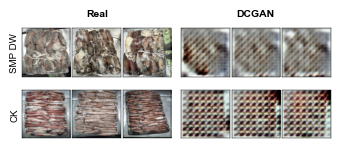

Grade,SMP DW,CK
Real images,201.0,278.0
DCGAN images,567.0,570.0
Augmented images,399.0,322.0
KID×1000 real vs DCGAN,889.1,701.9
KID×1000 real vs augmented,4.7,7.4
KID×1000 real vs real (two halves),-1.4,-0.5
FID real vs DCGAN,597.1,483.0
FID real vs augmented,41.3,32.4


In [6]:
# ===== 2. DCGAN samples (Fig. 3), FID and KID =====
def list_images(folder, skip_prefix=None):
    folder = Path(folder)
    if not folder.exists():
        print("MISSING:", rel(folder))
        return []
    return sorted(p for p in folder.iterdir()
                  if p.suffix.lower() in IMG_EXT and not (skip_prefix and p.name.startswith(skip_prefix)))


rng_p = np.random.default_rng(SEED)
fig = plt.figure(figsize=(3.45, 1.42))
gs = fig.add_gridspec(2, 7, width_ratios=[1, 1, 1, 0.12, 1, 1, 1], left=0.10, right=0.995, top=0.86,
                      bottom=0.02, wspace=0.05, hspace=0.06)
for r, c in enumerate(["SMP DW", "CK"]):
    for g0, folder, skip in [(0, "train", "aug_"), (4, "train_gan_sintesis", None)]:
        files = list_images(DATA_DIR / folder / c, skip_prefix=skip)
        pick3 = [files[i] for i in rng_p.choice(len(files), min(3, len(files)), replace=False)] if files else []
        for k in range(3):
            ax = fig.add_subplot(gs[r, g0 + k])
            ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_linewidth(0.3)
            if k < len(pick3):
                ax.imshow(Image.open(pick3[k]).convert("RGB").resize((128, 128), BILINEAR))
            if g0 == 0 and k == 0:
                ax.set_ylabel(c, fontsize=7, labelpad=2)
fig.text(0.10 + 0.895 * 1.5 / 6.12, 0.93, "Real", ha="center", va="center", fontsize=7.5, fontweight="bold")
fig.text(0.10 + 0.895 * 4.62 / 6.12, 0.93, "DCGAN", ha="center", va="center", fontsize=7.5, fontweight="bold")
fig.savefig(FIG_DIR / "fig3_dcgan.png", dpi=DPI); plt.show()

inc = tf.keras.applications.InceptionV3(include_top=False, pooling="avg", weights="imagenet", input_shape=(299, 299, 3))


def inception_feats(paths):
    feats, batch = [], []

    def flush():
        x = tf.keras.applications.inception_v3.preprocess_input(np.stack(batch).astype(np.float32))
        feats.append(np.asarray(inc.predict_on_batch(x)))

    for p in paths:
        im = Image.open(p).convert("RGB").resize((GAN_RES, GAN_RES), BILINEAR)
        batch.append(np.asarray(im.resize((299, 299), BILINEAR), dtype=np.float32))
        if len(batch) == 32:
            flush(); batch = []
    if batch:
        flush()
    return np.concatenate(feats)


rows = []
for c in ["SMP DW", "CK"]:
    real = list_images(DATA_DIR / "train" / c, skip_prefix="aug_")
    gan = list_images(DATA_DIR / "train_gan_sintesis" / c)
    aug = list_images(DATA_DIR / "train_augmented_sintesis" / c)
    if not (real and gan and aug):
        print(f"{c}: skipped, a folder is missing or empty")
        continue
    fr, fg, fa = inception_feats(real), inception_feats(gan), inception_feats(aug)
    perm = np.random.default_rng(SEED).permutation(len(fr))
    half = len(fr) // 2
    rows.append({"Grade": c, "Real images": len(real), "DCGAN images": len(gan), "Augmented images": len(aug),
                 "KID×1000 real vs DCGAN": 1000 * kid_score(fr, fg),
                 "KID×1000 real vs augmented": 1000 * kid_score(fr, fa),
                 "KID×1000 real vs real (two halves)": 1000 * kid_score(fr[perm[:half]], fr[perm[half:]]),
                 "FID real vs DCGAN": fid_score(fr, fg), "FID real vs augmented": fid_score(fr, fa)})
fk = pd.DataFrame(rows)
fk.to_csv(OUT_DIR / "fid_kid.csv", index=False)
show(fk.set_index("Grade").T.round(1))

## 3. Effect of class balancing (Sec. IV-B)

For the selected architecture, the retained S1, S2, and S3 configurations are compared on validation macro-F1 and with exact McNemar tests on the test set. For the other architectures, the spread of test macro-F1 across the three scenarios is taken from Table II.

In [7]:
# ===== 3. Scenarios: S1 vs S2 vs S3 =====
same = sel[sel["Model_Name"] == champ["Model_Name"]].sort_values("Skenario_Data")
print(f"{NAME[champ['Model_Name']]}: validation macro-F1 per scenario",
      {SCEN[r['Skenario_Data']]: round(float(r['Val_Macro_F1']), 4) for _, r in same.iterrows()},
      f"-> largest difference {same['Val_Macro_F1'].max() - same['Val_Macro_F1'].min():.3f}")
pred_s = {r["Skenario_Data"]: test_probs(r).argmax(1) for _, r in same.iterrows()}
names = sorted(pred_s)
for a in range(len(names)):
    for b in range(a + 1, len(names)):
        mcnemar_row(f"{NAME[champ['Model_Name']]} {SCEN[names[a]]} vs {SCEN[names[b]]}", pred_s[names[a]], pred_s[names[b]])

_rows = []
for _name, g in table2[table2["Model"] != NAME[champ["Model_Name"]]].groupby("Model", sort=False):
    _rows.append({"Model": _name, "Test M-F1 spread": g["Test M-F1"].max() - g["Test M-F1"].min(),
                  "Best scenario": g.loc[g["Test M-F1"].idxmax(), "Sc."]})
spread = pd.DataFrame(_rows).set_index("Model")
show(spread.round(3))
print(f"Spread across scenarios for the other models: {spread['Test M-F1 spread'].min():.3f}–"
      f"{spread['Test M-F1 spread'].max():.3f} in test macro-F1")

EfficientNet-B0: validation macro-F1 per scenario {'S1': 0.9325, 'S2': 0.9301, 'S3': 0.934} -> largest difference 0.004
EfficientNet-B0 S1 vs S2: 11 vs 12 discordant images, exact McNemar p = 1.000
EfficientNet-B0 S1 vs S3: 5 vs 7 discordant images, exact McNemar p = 0.774
EfficientNet-B0 S2 vs S3: 8 vs 9 discordant images, exact McNemar p = 1.000


,Test M-F1 spread,Best scenario
Model,,
Custom CNN,0.011,S1
ResNet50,0.006,S2
InceptionV3,0.030,S2
MobileNetV3-Small,0.001,S3
EfficientNet-B3,0.015,S2


Spread across scenarios for the other models: 0.001–0.030 in test macro-F1


## 4. Selected and fine-tuned models, error analysis (Sec. IV-C, Table III, Fig. 4)

Test results of the selected model with 95% CIs; comparisons with the best other architecture, with the configuration that has the highest test macro-F1, and with the fine-tuned EfficientNet-B0 of the earlier prototype; per-grade results (Table III) and the confusion between grades. The weights of the selected model are saved for the deployment code.

In [8]:
# ===== 4. Selected model, test-best configuration, fine-tuned model, Table III =====
pv_c, pt_c = cached_probs(champ, "val"), test_probs(champ)
yp_c = pt_c.argmax(1)
pred_m, conf_m = yp_c, pt_c.max(1)   # predicted grade and top probability on the test set
res_c = bootstrap_ci(y_test, yp_c)
print(f"Selected model {describe(champ)}")
print(f"  test accuracy {100 * res_c['acc']:.2f}% (95% CI {100 * res_c['acc_ci'][0]:.2f}–{100 * res_c['acc_ci'][1]:.2f}%), "
      f"macro-F1 {res_c['f1']:.3f} (95% CI {res_c['f1_ci'][0]:.3f}–{res_c['f1_ci'][1]:.3f})\n")
mcnemar_row(f"Selected vs {describe(runner)}", yp_c, test_probs(runner).argmax(1))

_m = np.ones(len(log), dtype=bool)
for _k, _v in TEST_BEST.items():
    _m &= np.isclose(log[_k], _v) if isinstance(_v, float) else (log[_k] == _v).to_numpy()
if _m.any():
    tbest = log[_m].iloc[-1]
else:
    print("TEST_BEST not found in the log; the row with the highest test macro-F1 is used instead")
    tbest = log.loc[log["Macro_F1_Score"].idxmax()]
print(f"\nHighest test macro-F1 in the log: {describe(tbest)}, {tbest['Macro_F1_Score']:.3f}"
      + ("" if np.isclose(tbest["Macro_F1_Score"], log["Macro_F1_Score"].max()) else
         f" (WARNING: the maximum in the log is {log['Macro_F1_Score'].max():.3f})"))
n01, n10, _ = mcnemar_row(f"Selected vs {describe(tbest)}", yp_c, test_probs(tbest).argmax(1))
print(f"  the two disagree on {n01 + n10} of {len(y_test)} test images")

pv_ft, pt_ft = finetuned_probs()
res_ft = bootstrap_ci(y_test, pt_ft.argmax(1))
print(f"\nFine-tuned EfficientNet-B0 ({FINETUNED_WEIGHTS.name}): validation macro-F1 "
      f"{macro_f1(y_val, pv_ft.argmax(1)):.3f} (selected model {macro_f1(y_val, pv_c.argmax(1)):.3f})")
print(f"  test accuracy {100 * res_ft['acc']:.2f}% (95% CI {100 * res_ft['acc_ci'][0]:.2f}–{100 * res_ft['acc_ci'][1]:.2f}%), "
      f"macro-F1 {res_ft['f1']:.3f} (95% CI {res_ft['f1_ci'][0]:.3f}–{res_ft['f1_ci'][1]:.3f})")
mcnemar_row("Selected vs fine-tuned EfficientNet-B0", yp_c, pt_ft.argmax(1))

print("\nTable III — per-grade test results of the deployed (selected) model")
print(classification_report(y_test, yp_c, labels=list(range(K)), target_names=CLASSES, digits=4, zero_division=0))
pd.DataFrame(classification_report(y_test, yp_c, labels=list(range(K)), target_names=CLASSES, digits=4,
                                   zero_division=0, output_dict=True)).T.to_csv(OUT_DIR / "table3_per_grade.csv")
cm = pd.DataFrame(confusion_matrix(y_test, yp_c, labels=list(range(K))),
                  index=[f"true {c}" for c in CLASSES], columns=[f"pred. {c}" for c in CLASSES])
cm.to_csv(OUT_DIR / "confusion_matrix.csv")
show(cm)
DW, UP = CLASSES.index("SMP DW"), CLASSES.index("SMP UP")
print(f"Errors: {int((yp_c != y_test).sum())} in total; SMP DW -> SMP UP {cm.iat[DW, UP]} of {int((y_test == DW).sum())}, "
      f"SMP UP -> SMP DW {cm.iat[UP, DW]} of {int((y_test == UP).sum())}")

model_c = build_model(champ["Model_Name"], float(champ["Dropout_Rate"]))
if not load_weights(model_c, tuned_path(champ)):
    raise RuntimeError("could not load the selected model")
model_c.save_weights(str(OUT_DIR / "Model_Terpilih_Frozen.weights.h5"))
print("\nWeights for the deployment code:", OUT_DIR / "Model_Terpilih_Frozen.weights.h5")

Selected model EfficientNet-B0, S3 (A, 10⁻³, 0.3)
  test accuracy 94.03% (95% CI 91.48–96.31%), macro-F1 0.919 (95% CI 0.883–0.949)

Selected vs EfficientNet-B3, S2 (R, 10⁻⁴, 0.5): 19 vs 9 discordant images, exact McNemar p = 0.087

Highest test macro-F1 in the log: EfficientNet-B0, S2 (R, 5×10⁻⁴, 0.3), 0.927
Selected vs EfficientNet-B0, S2 (R, 5×10⁻⁴, 0.3): 1 vs 3 discordant images, exact McNemar p = 0.625
  the two disagree on 4 of 352 test images

Fine-tuned EfficientNet-B0 (Model_Final_Juara.weights.h5): validation macro-F1 0.919 (selected model 0.934)
  test accuracy 92.61% (95% CI 89.77–95.45%), macro-F1 0.902 (95% CI 0.865–0.935)
Selected vs fine-tuned EfficientNet-B0: 8 vs 3 discordant images, exact McNemar p = 0.227

Table III — per-grade test results of the deployed (selected) model
              precision    recall  f1-score   support

      Cendol     1.0000    1.0000    1.0000       121
          CK     1.0000    1.0000    1.0000        60
      SMP DW     0.7674    0.7500

,pred. Cendol,pred. CK,pred. SMP DW,pred. SMP UP
true Cendol,121,0,0,0
true CK,0,60,0,0
true SMP DW,0,0,33,11
true SMP UP,0,0,10,117


Errors: 21 in total; SMP DW -> SMP UP 11 of 44, SMP UP -> SMP DW 10 of 127

Weights for the deployment code: results\Model_Terpilih_Frozen.weights.h5


findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

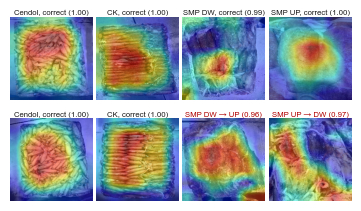

In [9]:
# ===== 4 (cont.). Grad-CAM maps of the deployed model (Fig. 4) =====
# With a GAP -> dense head, Grad-CAM equals the last feature map weighted by the dense weights of the predicted grade.
gap_layer = [l for l in model_c.layers if isinstance(l, layers.GlobalAveragePooling2D)][-1]
feat_model = tf.keras.Model(model_c.inputs, gap_layer.input)
W_dense = model_c.layers[-1].get_weights()[0]


def cam_for(i, cls):
    A = np.asarray(feat_model.predict_on_batch(np.array(X_test[i:i + 1], dtype=np.float32, copy=True)))[0]
    cam = np.maximum(A @ W_dense[:, cls], 0)
    cam = cam / (cam.max() + 1e-8)
    return tf.image.resize(cam[..., None], IMG_SIZE).numpy()[..., 0]


# top row: most confident correct image per grade; bottom row: second correct image (Cendol, CK)
# or the most confident error (SMP DW, SMP UP)
short = {c: c.replace("SMP ", "") for c in CLASSES}
order_conf = np.argsort(-conf_m)


def pick(c, k, wrong):
    idx = [i for i in order_conf if y_test[i] == c and ((pred_m[i] != c) if wrong else (pred_m[i] == c))]
    return idx[k] if len(idx) > k else None


top = [pick(c, 0, False) for c in range(K)]
bottom = []
for c in range(K):
    w = pick(c, 0, True) if CLASSES[c] in ("SMP DW", "SMP UP") else None
    bottom.append(w if w is not None else pick(c, 1, False))
fig, axes = plt.subplots(2, 4, figsize=(3.45, 2.02),
                         gridspec_kw=dict(left=0.005, right=0.995, top=0.94, bottom=0.01, wspace=0.04, hspace=0.17))
for r, row in enumerate([top, bottom]):
    for c, i in enumerate(row):
        ax = axes[r, c]
        ax.axis("off")
        if i is None:
            continue
        ax.imshow(np.clip(X_test[i] / 255.0, 0, 1))
        ax.imshow(cam_for(i, int(pred_m[i])), cmap="jet", alpha=0.45)
        ok = pred_m[i] == y_test[i]
        title = (f"{CLASSES[y_test[i]]}, correct ({conf_m[i]:.2f})" if ok else
                 f"{CLASSES[y_test[i]]} → {short[CLASSES[pred_m[i]]]} ({conf_m[i]:.2f})")
        ax.set_title(title, fontsize=5.6, pad=1.5, color="#1a1a1a" if ok else "#b00000")
fig.savefig(FIG_DIR / "fig4_gradcam.png", dpi=DPI); plt.show()

## 5. Confidence gate and calibration (Sec. IV-D, Fig. 5)

τ is the lowest threshold whose selective risk on the validation set is at most 2%. On the test set, coverage is the share of images whose top probability reaches τ and selective risk is the error among them, for τ and for the earlier heuristic 0.75. Calibration is measured with the ECE (15 bins) before and after temperature scaling fitted on the validation set.

findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

tau chosen on validation (selective risk <= 2%): 0.78
  test: 300 of 352 images accepted (coverage 85.2%), error among them 2.7%, error without the gate 5.97%
tau = 0.75: coverage 87.2%, error 2.9%
SMP DW–SMP UP confusions: 21, withheld by the gate: 13, passed: 8 (confidence 0.78–0.97)

Test ECE 0.026; after temperature scaling (T = 0.93) 0.022


findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

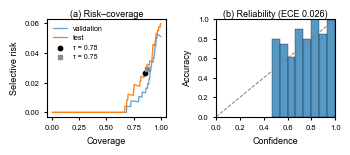

In [10]:
# ===== 5. Confidence gate, calibration, and Fig. 5 =====
taus = np.round(np.arange(0.30, 1.00, 0.01), 2)
gv, gt = gate_table(pv_c, y_val, taus), gate_table(pt_c, y_test, taus)
gv.to_csv(OUT_DIR / "gate_validation.csv", index=False); gt.to_csv(OUT_DIR / "gate_test.csv", index=False)
tau_star = pick_tau(gv)
g_star = gt[gt["tau"] == round(tau_star, 2)].iloc[0]
g_075 = gt[gt["tau"] == TAU_EARLIER].iloc[0]
print(f"tau chosen on validation (selective risk <= {TARGET_RISK:.0%}): {tau_star:.2f}")
print(f"  test: {int(g_star['accepted'])} of {len(y_test)} images accepted (coverage {100 * g_star['coverage']:.1f}%), "
      f"error among them {100 * g_star['risk']:.1f}%, error without the gate {100 * np.mean(pred_m != y_test):.2f}%")
print(f"tau = {TAU_EARLIER:.2f}: coverage {100 * g_075['coverage']:.1f}%, error {100 * g_075['risk']:.1f}%")

dwup = (pred_m != y_test) & np.isin(y_test, [DW, UP]) & np.isin(pred_m, [DW, UP])
held = dwup & (conf_m < tau_star)
passed = dwup & ~held
print(f"SMP DW–SMP UP confusions: {int(dwup.sum())}, withheld by the gate: {int(held.sum())}, "
      f"passed: {int(passed.sum())} (confidence {conf_m[passed].min():.2f}–{conf_m[passed].max():.2f})"
      if passed.any() else f"SMP DW–SMP UP confusions: {int(dwup.sum())}, all withheld by the gate")

T_opt = fit_temperature(pv_c, y_val)
ece0, bins0 = ece_score(pt_c, y_test)
ece1, _ = ece_score(apply_temperature(pt_c, T_opt), y_test)
print(f"\nTest ECE {ece0:.3f}; after temperature scaling (T = {T_opt:.2f}) {ece1:.3f}")

cov_v, risk_v = risk_coverage_curve(pv_c, y_val)
cov_t, risk_t = risk_coverage_curve(pt_c, y_test)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(3.45, 1.55),
                             gridspec_kw=dict(left=0.13, right=0.965, top=0.88, bottom=0.25, wspace=0.42))
a1.plot(cov_v, risk_v, lw=0.9, alpha=0.7, label="validation")
a1.plot(cov_t, risk_t, lw=0.9, label="test")
a1.scatter([g_star["coverage"]], [g_star["risk"]], s=10, zorder=3, color="black", label=f"τ = {tau_star:.2f}")
a1.scatter([g_075["coverage"]], [g_075["risk"]], s=10, marker="s", zorder=3, color="#8c8c8c", label=f"τ = {TAU_EARLIER:.2f}")
a1.set_xlabel("Coverage", fontsize=6.5); a1.set_ylabel("Selective risk", fontsize=6.5)
a1.set_title("(a) Risk–coverage", fontsize=6.5, pad=2)
a1.legend(fontsize=5, frameon=False, loc="upper left")
mids = [(lo + hi) / 2 for lo, hi, *_ in bins0]
a2.bar(mids, [acc for *_, acc, _ in bins0], width=1 / ECE_BINS, edgecolor="black", linewidth=0.3, alpha=0.75)
a2.plot([0, 1], [0, 1], "--", color="gray", lw=0.7)
a2.set_xlim(0, 1); a2.set_ylim(0, 1)
a2.set_xlabel("Confidence", fontsize=6.5); a2.set_ylabel("Accuracy", fontsize=6.5)
a2.set_title(f"(b) Reliability (ECE {ece0:.3f})", fontsize=6.5, pad=2)
for ax in (a1, a2):
    ax.tick_params(labelsize=5.5, length=2)
fig.savefig(FIG_DIR / "fig5_gate_calibration.png", dpi=DPI); plt.show()

## 6. Numbers reported in the paper

All values above, collected with their place in the paper and saved to `results/paper_numbers.csv`.

In [11]:
# ===== 6. Summary of the reported numbers =====
pct = lambda x: f"{100 * x:.2f}%"
ci_pct = lambda c: f"{100 * c[0]:.2f}–{100 * c[1]:.2f}%"
ci3 = lambda c: f"{c[0]:.3f}–{c[1]:.3f}"
mc = {r["Comparison"]: r for r in MC_ROWS}
b0_p = [r["p (exact)"] for k, r in mc.items() if k.startswith(NAME[champ["Model_Name"]] + " S")]
N = [
    ("Sec. III-D", "Runs (unique configurations)", len(log)),
    ("Sec. III-D", "Runs reproducing the logged validation accuracy", int(log["Matches_Log"].sum())),
    ("Table II", "Retained configurations", f"{len(table2)} (table2_selected_configurations.csv)"),
]
for _, r in fk.iterrows():
    N += [("Sec. IV-A", f"KID×1000 real vs DCGAN, {r['Grade']}", f"{r['KID×1000 real vs DCGAN']:.0f}"),
          ("Sec. IV-A", f"KID×1000 real vs augmented, {r['Grade']}", f"{r['KID×1000 real vs augmented']:.1f}"),
          ("Sec. IV-A", f"KID×1000 real vs real halves, {r['Grade']}", f"{r['KID×1000 real vs real (two halves)']:.1f}"),
          ("Sec. IV-A", f"FID real vs DCGAN / augmented, {r['Grade']}",
           f"{r['FID real vs DCGAN']:.0f} / {r['FID real vs augmented']:.0f}")]
N += [
    ("Sec. IV-B", f"{NAME[champ['Model_Name']]}: largest validation macro-F1 difference between scenarios",
     f"{same['Val_Macro_F1'].max() - same['Val_Macro_F1'].min():.3f}"),
    ("Sec. IV-B", f"{NAME[champ['Model_Name']]}: smallest McNemar p between scenarios", f"{min(b0_p):.2f}"),
    ("Sec. IV-B", "Other models: spread of test macro-F1 across scenarios",
     f"{spread['Test M-F1 spread'].min():.3f}–{spread['Test M-F1 spread'].max():.3f}"),
    ("Sec. IV-C", "Selected model", f"{describe(champ)}; validation macro-F1 {champ['Val_Macro_F1']:.3f}"),
    ("Sec. IV-C", "McNemar p vs best other architecture", f"{mc[f'Selected vs {describe(runner)}']['p (exact)']:.3f}"),
    ("Sec. IV-C", "Test accuracy (95% CI)", f"{pct(res_c['acc'])} ({ci_pct(res_c['acc_ci'])})"),
    ("Sec. IV-C", "Test macro-F1 (95% CI)", f"{res_c['f1']:.3f} ({ci3(res_c['f1_ci'])})"),
    ("Sec. IV-C", "Highest test macro-F1 configuration", f"{describe(tbest)}; {tbest['Macro_F1_Score']:.3f}"),
    ("Sec. IV-C", "  disagreement with the selected model, McNemar p",
     f"{n01 + n10} of {len(y_test)} images, p = {mc[f'Selected vs {describe(tbest)}']['p (exact)']:.3f}"),
    ("Sec. IV-C", "Fine-tuned: validation macro-F1", f"{macro_f1(y_val, pv_ft.argmax(1)):.3f}"),
    ("Sec. IV-C", "Fine-tuned: test accuracy (95% CI)", f"{pct(res_ft['acc'])} ({ci_pct(res_ft['acc_ci'])})"),
    ("Sec. IV-C", "Fine-tuned: test macro-F1 (95% CI)", f"{res_ft['f1']:.3f} ({ci3(res_ft['f1_ci'])})"),
    ("Sec. IV-C", "McNemar p selected vs fine-tuned", f"{mc['Selected vs fine-tuned EfficientNet-B0']['p (exact)']:.3f}"),
    ("Table III", "Per-grade results", "table3_per_grade.csv"),
    ("Sec. IV-C", "Errors (SMP DW -> SMP UP, SMP UP -> SMP DW)",
     f"{int((yp_c != y_test).sum())} ({cm.iat[DW, UP]} of {int((y_test == DW).sum())}, {cm.iat[UP, DW]} of {int((y_test == UP).sum())})"),
    ("Sec. IV-D", "tau chosen on validation", f"{tau_star:.2f}"),
    ("Sec. IV-D", "Accepted test images, coverage, error",
     f"{int(g_star['accepted'])} of {len(y_test)}, {100 * g_star['coverage']:.1f}%, {100 * g_star['risk']:.1f}%"),
    ("Sec. IV-D", "Error without the gate", f"{100 * np.mean(pred_m != y_test):.2f}%"),
    ("Sec. IV-D", "SMP DW–SMP UP confusions withheld / passed", f"{int(held.sum())} of {int(dwup.sum())} / {int(passed.sum())}"),
    ("Sec. IV-D", f"tau = {TAU_EARLIER:.2f}: coverage, error", f"{100 * g_075['coverage']:.1f}%, {100 * g_075['risk']:.1f}%"),
    ("Sec. IV-D", "Test ECE; after temperature scaling (T)", f"{ece0:.3f}; {ece1:.3f} (T = {T_opt:.2f})"),
]
summary = pd.DataFrame(N, columns=["Paper", "Quantity", "Value"])
summary.to_csv(OUT_DIR / "paper_numbers.csv", index=False)
show(summary)
print("\nFigures:", ", ".join(p.name for p in sorted(FIG_DIR.glob("*.png"))))

,Paper,Quantity,Value
0,Sec. III-D,Runs (unique configurations),324
1,Sec. III-D,Runs reproducing the logged validation accuracy,324
2,Table II,Retained configurations,18 (table2_selected_configurations.csv)
3,Sec. IV-A,"KID×1000 real vs DCGAN, SMP DW",889
4,Sec. IV-A,"KID×1000 real vs augmented, SMP DW",4.7
5,Sec. IV-A,"KID×1000 real vs real halves, SMP DW",-1.4
6,Sec. IV-A,"FID real vs DCGAN / augmented, SMP DW",597 / 41
7,Sec. IV-A,"KID×1000 real vs DCGAN, CK",702
8,Sec. IV-A,"KID×1000 real vs augmented, CK",7.4
9,Sec. IV-A,"KID×1000 real vs real halves, CK",-0.5



Figures: fig3_dcgan.png, fig4_gradcam.png, fig5_gate_calibration.png
